# ViT + ConvNeXt + Weighted Ensemble + Stacking

In [ ]:
# =========================
# CELL 1 — Imports + Seed + Paths + Device + Quick counts
# =========================
import os, glob, random, json
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from transformers import ViTForImageClassification
from transformers import get_cosine_schedule_with_warmup

import timm
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt
from tqdm import tqdm


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

# ---- paths ----
train_dir = "/content/drive/MyDrive/Thesis_project/datasets/train"
val_dir   = "/content/drive/MyDrive/Thesis_project/datasets/val"
test_dir  = "/content/drive/MyDrive/Thesis_project/datasets/test"

SAVE_DIR = "/content/drive/MyDrive/Thesis_project/models"
os.makedirs(SAVE_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ device:", device)
print("✅ SAVE_DIR:", SAVE_DIR)


def count_images(root):
    exts = (".png",".jpg",".jpeg",".bmp",".webp")
    n = 0
    for c in os.listdir(root):
        cp = os.path.join(root, c)
        if not os.path.isdir(cp):
            continue
        for fn in os.listdir(cp):
            if fn.lower().endswith(exts):
                n += 1
    return n

print("📦 Train images:", count_images(train_dir))
print("📦 Val images  :", count_images(val_dir))
print("📦 Test images :", count_images(test_dir))

# build class map from TRAIN ONLY
train_base = datasets.ImageFolder(root=train_dir)
classes = train_base.classes
class_to_idx = train_base.class_to_idx
num_classes = len(classes)

print(f"✅ Found {num_classes} classes.")
print("✅ Example class:", classes[0])



✅ device: cuda
✅ SAVE_DIR: /content/drive/MyDrive/Thesis_project/models
📦 Train images: 11904
📦 Val images  : 1949
📦 Test images : 1047
✅ Found 496 classes.
✅ Example class: Abhaynagar Upazila,Jashore


In [ ]:
# =========================
# CELL 2 — Optional crop
# =========================
USE_CROP = False

def crop_text_area_pil(img: Image.Image, pad=6):
    arr = np.array(img.convert("RGB"))
    gray = np.array(img.convert("L"))

    thr = np.percentile(gray, 85)
    mask = gray < thr
    coords = np.argwhere(mask)

    if coords.size == 0:
        return img

    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0)

    y0 = max(0, y0 - pad); x0 = max(0, x0 - pad)
    y1 = min(arr.shape[0]-1, y1 + pad); x1 = min(arr.shape[1]-1, x1 + pad)

    if (y1 - y0) < 20 or (x1 - x0) < 20:
        return img

    crop = arr[y0:y1+1, x0:x1+1]
    return Image.fromarray(crop)


# =========================
# CELL 3 — Dataset that returns path (shared)
# =========================
class ImageFolderWithPath(datasets.ImageFolder):
    def __getitem__(self, index):
        img, label = super().__getitem__(index)
        path, _ = self.samples[index]
        return img, label, path

In [ ]:
# =========================
# CELL-4 Transforms + Loaders (single shared set, 224, ImageNet norm)
# =========================
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
print("✅ Using ImageNet mean/std:", mean, std)

train_transform = transforms.Compose([
    transforms.Lambda(lambda im: crop_text_area_pil(im) if USE_CROP else im),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(5),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), shear=5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.08), ratio=(0.3, 3.3)),
])

val_transform = transforms.Compose([
    transforms.Lambda(lambda im: crop_text_area_pil(im) if USE_CROP else im),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = ImageFolderWithPath(train_dir, transform=train_transform)
val_ds   = ImageFolderWithPath(val_dir,   transform=val_transform)
test_ds  = ImageFolderWithPath(test_dir,  transform=val_transform)

assert train_ds.class_to_idx == train_base.class_to_idx, "Train mapping changed unexpectedly."
assert val_ds.class_to_idx == train_base.class_to_idx, "Val classes mismatch vs train."
assert test_ds.class_to_idx == train_base.class_to_idx, "Test classes mismatch vs train."

batch_size  = 32
num_workers = 2

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                          num_workers=num_workers, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                          num_workers=num_workers, pin_memory=True)

print("✅ Loaders ready:", len(train_loader), len(val_loader), len(test_loader))

✅ Using ImageNet mean/std: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
✅ Loaders ready: 372 61 33


# PART A — Vision Transfer model (ViT)

In [ ]:
# =========================
# CELL A1 — Loss
# =========================
USE_FOCAL = False
LABEL_SMOOTHING = 0.10

class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, target):
        log_probs = F.log_softmax(logits, dim=1)
        probs = log_probs.exp()
        pt = probs[torch.arange(target.size(0), device=target.device), target]
        logpt = log_probs[torch.arange(target.size(0), device=target.device), target]
        loss = -self.alpha * (1 - pt)**self.gamma * logpt
        return loss.mean() if self.reduction == "mean" else loss.sum()

def hard_criterion():
    if USE_FOCAL:
        return FocalLoss(alpha=1.0, gamma=2.0)
    return nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

print("✅ ViT Loss ready. Focal:", USE_FOCAL, "| Label smoothing:", LABEL_SMOOTHING)


# =========================
# CELL A2 — Mixup
# =========================
USE_MIXUP_VIT = True

mixup_fn_vit = None
mixup_train_criterion_vit = None

if USE_MIXUP_VIT:
    mixup_fn_vit = Mixup(
        mixup_alpha=0.1,
        cutmix_alpha=0.0,       # disable CutMix
        prob=0.5,
        switch_prob=0.0,
        mode="batch",
        label_smoothing=0.0,    # don't mix label smoothing with mixup
        num_classes=num_classes,
    )
    mixup_train_criterion_vit = SoftTargetCrossEntropy()
    print("✅ ViT Mixup enabled (CutMix disabled).")
else:
    print("✅ ViT Mixup disabled.")


✅ ViT Loss ready. Focal: False | Label smoothing: 0.1
✅ ViT Mixup enabled (CutMix disabled).


In [ ]:

# =========================
# CELL A3 — Build ViT
# =========================
def build_vit_base_custom_head(num_classes, dropout=0.30, hidden_ratio=0.5):
    model = ViTForImageClassification.from_pretrained(
        "google/vit-base-patch16-224",
        num_labels=num_classes,
        ignore_mismatched_sizes=True
    )

    model.config.num_labels = num_classes
    model.num_labels = num_classes

    hidden = model.config.hidden_size
    mid = int(hidden * hidden_ratio)

    model.classifier = nn.Sequential(
        nn.LayerNorm(hidden),
        nn.Dropout(dropout),
        nn.Linear(hidden, mid),
        nn.GELU(),
        nn.Dropout(dropout),
        nn.Linear(mid, num_classes),
    )
    return model

vit = build_vit_base_custom_head(num_classes=num_classes, dropout=0.30, hidden_ratio=0.5)
VIT_SAVE = os.path.join(SAVE_DIR, "best_vit_base_custom_mlp.pth")
print("✅ ViT ready. Will save to:", VIT_SAVE)


# =========================
# CELL A4 — ViT training
# =========================
def get_logits(model, x):
    out = model(x)
    return out.logits if hasattr(out, "logits") else out

@torch.no_grad()
def topk_acc_from_logits(logits, y, k=5):
    topk = torch.topk(logits, k=k, dim=1).indices
    return (topk == y.unsqueeze(1)).any(dim=1).float().mean().item()

def set_backbone_trainable_vit(model, trainable: bool):
    for name, p in model.named_parameters():
        if "classifier" in name:
            p.requires_grad = True
        else:
            p.requires_grad = trainable

def train_model_two_stage(
    model,
    train_loader,
    val_loader,
    save_path,
    head_epochs=1,
    full_epochs=10,
    head_lr=3e-4,
    full_lr=2e-4,
    weight_decay=0.05,
    print_every=50,
    mixup_start_epoch=2
):
    model = model.to(device)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_top5": [],
        "lr": []
    }
    best_val = 0.0

    use_amp = (device.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    def run_epochs(stage_name, epochs, lr, backbone_trainable):
        nonlocal best_val, history
        set_backbone_trainable_vit(model, backbone_trainable)

        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=lr,
            weight_decay=weight_decay
        )

        total_steps = epochs * len(train_loader)
        warmup_steps = max(1, int(0.05 * total_steps))
        scheduler = get_cosine_schedule_with_warmup(
            optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps
        )

        hard_loss = hard_criterion()

        for epoch in range(1, epochs + 1):
            global_epoch = len(history["train_loss"]) + 1
            model.train()

            running_loss = 0.0
            correct = 0
            total = 0

            pbar = tqdm(train_loader, total=len(train_loader),
                        desc=f"🟢 {stage_name} Epoch {epoch}/{epochs} (train)")
            for step, (images, labels, _paths) in enumerate(pbar, start=1):
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                do_mix = (USE_MIXUP_VIT and (global_epoch >= mixup_start_epoch) and (mixup_fn_vit is not None))
                if do_mix:
                    images, targets = mixup_fn_vit(images, labels)
                    criterion_train = mixup_train_criterion_vit
                else:
                    targets = labels
                    criterion_train = hard_loss

                optimizer.zero_grad(set_to_none=True)

                with torch.cuda.amp.autocast(enabled=use_amp):
                    logits = get_logits(model, images)
                    loss = criterion_train(logits, targets)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

                scheduler.step()

                running_loss += loss.item() * images.size(0)
                preds = logits.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

                if step % print_every == 0:
                    pbar.set_postfix(
                        loss=float(loss.item()),
                        acc=float(correct / total),
                        lr=float(optimizer.param_groups[0]["lr"])
                    )

            train_loss = running_loss / total
            train_acc = correct / total

            # ---- val ----
            model.eval()
            v_correct, v_total = 0, 0
            v_top5_sum = 0.0
            with torch.no_grad():
                for images, labels, _paths in tqdm(val_loader, desc=f"🔍 {stage_name} (val)", leave=False):
                    images = images.to(device, non_blocking=True)
                    labels = labels.to(device, non_blocking=True)
                    logits = get_logits(model, images)
                    preds = logits.argmax(dim=1)
                    v_correct += (preds == labels).sum().item()
                    v_total += labels.size(0)
                    v_top5_sum += topk_acc_from_logits(logits, labels, k=5) * labels.size(0)

            val_acc = v_correct / v_total
            val_top5 = v_top5_sum / v_total
            cur_lr = optimizer.param_groups[0]["lr"]

            history["train_loss"].append(train_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)
            history["val_top5"].append(val_top5)
            history["lr"].append(cur_lr)

            print(f"\n✅ {stage_name} Epoch {epoch}: "
                  f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
                  f"val_acc={val_acc:.4f} val_top5={val_top5:.4f}")

            if val_acc > best_val:
                best_val = val_acc
                torch.save(model.state_dict(), save_path)
                print(f"💾 Saved BEST -> {save_path} (val_acc={best_val:.4f})")

    print("✅ Stage A: head-only warmup")
    run_epochs("ViT-Base (head-only)", head_epochs, head_lr, backbone_trainable=False)

    print("✅ Stage B: full fine-tune")
    run_epochs("ViT-Base (full)", full_epochs, full_lr, backbone_trainable=True)

    return history, best_val


# =========================
# CELL A5 — Train ViT
# =========================
vit_history, vit_best = train_model_two_stage(
    vit,
    train_loader, val_loader,
    save_path=VIT_SAVE,
    head_epochs=2,
    full_epochs=15,
    head_lr=3e-4,
    full_lr=2e-4,
    weight_decay=0.05,
    print_every=50,
    mixup_start_epoch=2
)

print("✅ ViT best val acc:", vit_best)
print("✅ ViT best path:", VIT_SAVE)

# Guarantee a backup file exists
VIT_FINAL_BACKUP = os.path.join(SAVE_DIR, "vit_FINAL_backup.pth")
torch.save(vit.state_dict(), VIT_FINAL_BACKUP)
print("✅ Saved ViT FINAL backup:", VIT_FINAL_BACKUP)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([496])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([496, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


✅ ViT ready. Will save to: /content/drive/MyDrive/Thesis_project/models/best_vit_base_custom_mlp.pth


... (32 outputs left out)

🟢 ViT-Base (full) Epoch 14/15 (train): 100%|██████████| 372/372 [02:05<00:00,  2.96it/s, acc=0.739, loss=0.0823, lr=2.71e-6]



✅ ViT-Base (full) Epoch 14: train_loss=0.5272 train_acc=0.7375 val_acc=0.9241 val_top5=0.9903
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_vit_base_custom_mlp.pth (val_acc=0.9241)


🟢 ViT-Base (full) Epoch 15/15 (train): 100%|██████████| 372/372 [02:05<00:00,  2.96it/s, acc=0.735, loss=0.131, lr=8.5e-9]



✅ ViT-Base (full) Epoch 15: train_loss=0.4388 train_acc=0.7440 val_acc=0.9230 val_top5=0.9903
✅ ViT best val acc: 0.9240636223704464
✅ ViT best path: /content/drive/MyDrive/Thesis_project/models/best_vit_base_custom_mlp.pth
✅ Saved ViT FINAL backup: /content/drive/MyDrive/Thesis_project/models/vit_FINAL_backup.pth


# PART B — ConvNeXt

In [ ]:
# =========================
# CELL B1 — Mixup + Loss
# =========================
USE_MIXUP = True

mixup_fn = None
train_criterion = None

if USE_MIXUP:
    mixup_fn = Mixup(
        mixup_alpha=0.1,
        cutmix_alpha=0.0,     # disable CutMix
        prob=0.5,
        switch_prob=0.0,
        mode="batch",
        label_smoothing=0.0,
        num_classes=num_classes,
    )
    train_criterion = SoftTargetCrossEntropy()
    print("✅ ConvNeXt Mixup enabled (CutMix disabled).")
else:
    print("✅ ConvNeXt Mixup disabled.")

LABEL_SMOOTHING = 0.10
val_criterion = nn.CrossEntropyLoss()

def hard_train_criterion(logits, y):
    return F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING)

@torch.no_grad()
def topk_accuracy(logits, y, k=5):
    topk = torch.topk(logits, k=k, dim=1).indices
    return (topk == y.unsqueeze(1)).any(dim=1).float().mean().item()


# =========================
# CELL B2 — ConvNeXt model
# =========================
class ConvNeXtCustom(nn.Module):
    def __init__(self, model_name: str, num_classes: int, dropout=0.30, hidden_ratio=0.5, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=0,
            global_pool=""
        )

        self.hidden = getattr(self.backbone, "num_features", None)
        if self.hidden is None:
            raise ValueError("Could not find backbone.num_features (unexpected timm model).")

        mid = int(self.hidden * hidden_ratio)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.LayerNorm(self.hidden),
            nn.Dropout(dropout),
            nn.Linear(self.hidden, mid),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mid, num_classes)
        )

    def forward(self, x):
        feats = self.backbone.forward_features(x)

        if feats.dim() == 4:
            if feats.shape[1] != self.hidden and feats.shape[-1] == self.hidden:
                feats = feats.permute(0, 3, 1, 2).contiguous()
            feats = self.pool(feats).flatten(1)
        elif feats.dim() == 2:
            pass
        else:
            raise RuntimeError(f"Unexpected feature shape: {feats.shape}")

        return self.head(feats)

def build_convnext_custom_head(num_classes, variant="tiny", dropout=0.30, hidden_ratio=0.5, pretrained=True):
    model_name = "convnext_tiny" if variant == "tiny" else "convnext_base"
    return ConvNeXtCustom(
        model_name=model_name,
        num_classes=num_classes,
        dropout=dropout,
        hidden_ratio=hidden_ratio,
        pretrained=pretrained
    )


# =========================
# CELL B3 — Train helpers
# =========================
from contextlib import contextmanager

def make_scaler(use_amp: bool):
    try:
        return torch.amp.GradScaler('cuda', enabled=use_amp)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=use_amp)

@contextmanager
def autocast_ctx(use_amp: bool):
    if not use_amp:
        yield
        return
    try:
        with torch.amp.autocast('cuda', enabled=True):
            yield
    except Exception:
        with torch.cuda.amp.autocast(enabled=True):
            yield

def lr_at_step(base_lr, step, total_steps, warmup_steps):
    if step < warmup_steps:
        return base_lr * (step + 1) / max(1, warmup_steps)
    t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + np.cos(np.pi * t))

def freeze_backbone_only_train_head(model: nn.Module):
    for p in model.backbone.parameters():
        p.requires_grad = False
    for p in model.head.parameters():
        p.requires_grad = True

def unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True

def train_one_model(
    model_name, model, train_loader, val_loader,
    epochs=10, lr=2e-4, weight_decay=0.05,
    warmup_ratio=0.05,
    save_path=None,
    print_every=50
):
    model = model.to(device)
    use_amp = (device.type == "cuda")
    scaler = make_scaler(use_amp)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    total_steps = epochs * len(train_loader)
    warmup_steps = int(total_steps * warmup_ratio)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_top5": []
    }
    best_val = 0.0
    global_step = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        pbar = tqdm(train_loader, total=len(train_loader),
                    desc=f"🟢 {model_name} Epoch {epoch}/{epochs} (train)")
        for step, (images, labels, _paths) in enumerate(pbar, start=1):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            lr_now = lr_at_step(lr, global_step, total_steps, warmup_steps)
            for pg in optimizer.param_groups:
                pg["lr"] = lr_now

            optimizer.zero_grad(set_to_none=True)

            if USE_MIXUP and mixup_fn is not None:
                images, targets = mixup_fn(images, labels)
                criterion = train_criterion
            else:
                targets = labels
                criterion = hard_train_criterion

            with autocast_ctx(use_amp):
                logits = model(images)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)

            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            global_step += 1

            if step % print_every == 0:
                pbar.set_postfix(loss=float(loss.item()), acc=float(correct/total), lr=float(lr_now))

        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        v_correct, v_total, v_top5_sum = 0, 0, 0.0

        with torch.no_grad():
            for images, labels, _paths in tqdm(val_loader, desc=f"🔍 {model_name} (val)", leave=False):
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                logits = model(images)
                preds = logits.argmax(dim=1)

                v_correct += (preds == labels).sum().item()
                v_total += labels.size(0)
                v_top5_sum += topk_accuracy(logits, labels, k=5) * labels.size(0)

        val_acc = v_correct / v_total
        val_top5 = v_top5_sum / v_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_top5"].append(val_top5)

        print(f"\n✅ {model_name} Epoch {epoch}: "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
              f"val_acc={val_acc:.4f} val_top5={val_top5:.4f}")

        if val_acc > best_val:
            best_val = val_acc
            if save_path:
                torch.save(model.state_dict(), save_path)
                print(f"💾 Saved BEST -> {save_path} (val_acc={best_val:.4f})")

    return history, best_val


# =========================
# CELL B4 — Build + Train ConvNeXt
# =========================
CONVNEXT_VARIANT = "tiny"

convnext = build_convnext_custom_head(
    num_classes=num_classes,
    variant=CONVNEXT_VARIANT,
    dropout=0.30,
    hidden_ratio=0.5,
    pretrained=True
)

CONVNEXT_SAVE = os.path.join(SAVE_DIR, f"best_convnext_{CONVNEXT_VARIANT}_custom_mlp.pth")
print("✅ ConvNeXt ready:", CONVNEXT_VARIANT)
print("💾 Will save to:", CONVNEXT_SAVE)

# Stage A: head-only warmup
freeze_backbone_only_train_head(convnext)
print("✅ Stage A: ConvNeXt head-only warmup")
hist_a, best_a = train_one_model(
    f"ConvNeXt-{CONVNEXT_VARIANT} (head-only)",
    convnext,
    train_loader,
    val_loader,
    epochs=2,
    lr=3e-4,
    weight_decay=0.05,
    warmup_ratio=0.10,
    save_path=CONVNEXT_SAVE,
    print_every=50
)

# Stage B: full fine-tune
unfreeze_all(convnext)
print("✅ Stage B: ConvNeXt full fine-tune")
hist_b, best_b = train_one_model(
    f"ConvNeXt-{CONVNEXT_VARIANT} (full)",
    convnext,
    train_loader,
    val_loader,
    epochs=12,
    lr=5e-5,
    weight_decay=0.05,
    warmup_ratio=0.05,
    save_path=CONVNEXT_SAVE,
    print_every=50
)

convnext_best_val = max(best_a, best_b)
print("✅ Best ConvNeXt val acc:", convnext_best_val)
print("✅ Saved best ConvNeXt checkpoint to:", CONVNEXT_SAVE)

# Guarantee a backup file exists
CONVNEXT_FINAL_BACKUP = os.path.join(SAVE_DIR, f"convnext_{CONVNEXT_VARIANT}_FINAL_backup.pth")
torch.save(convnext.state_dict(), CONVNEXT_FINAL_BACKUP)
print("✅ Saved ConvNeXt FINAL backup:", CONVNEXT_FINAL_BACKUP)


✅ ConvNeXt Mixup enabled (CutMix disabled).


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

✅ ConvNeXt ready: tiny
💾 Will save to: /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth
✅ Stage A: ConvNeXt head-only warmup


🟢 ConvNeXt-tiny (head-only) Epoch 1/2 (train): 100%|██████████| 372/372 [01:41<00:00,  3.67it/s, acc=0.00295, loss=6.16, lr=0.000192]



✅ ConvNeXt-tiny (head-only) Epoch 1: train_loss=6.2063 train_acc=0.0032 val_acc=0.0051 val_top5=0.0231
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth (val_acc=0.0051)


🟢 ConvNeXt-tiny (head-only) Epoch 2/2 (train): 100%|██████████| 372/372 [01:35<00:00,  3.89it/s, acc=0.00661, loss=6.07, lr=8.71e-7]


... (21 outputs left out)

🟢 ConvNeXt-tiny (full) Epoch 11/12 (train): 100%|██████████| 372/372 [01:47<00:00,  3.45it/s, acc=0.751, loss=4.33, lr=1.06e-6]



✅ ConvNeXt-tiny (full) Epoch 11: train_loss=0.5761 train_acc=0.7388 val_acc=0.9600 val_top5=0.9908
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth (val_acc=0.9600)


🟢 ConvNeXt-tiny (full) Epoch 12/12 (train): 100%|██████████| 372/372 [01:50<00:00,  3.36it/s, acc=0.733, loss=0.214, lr=3.63e-9]



✅ ConvNeXt-tiny (full) Epoch 12: train_loss=0.6384 train_acc=0.7443 val_acc=0.9605 val_top5=0.9908
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth (val_acc=0.9605)
✅ Best ConvNeXt val acc: 0.9604925602873269
✅ Saved best ConvNeXt checkpoint to: /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth
✅ Saved ConvNeXt FINAL backup: /content/drive/MyDrive/Thesis_project/models/convnext_tiny_FINAL_backup.pth


In [ ]:
# ============================================================
# CELL D — Swin Transformer Base
# Compatible with existing train_one_model (no mixup kwargs)
# ============================================================

class SwinCustom(nn.Module):
    def __init__(self, model_name: str, num_classes: int, dropout=0.30, hidden_ratio=0.5, pretrained=True):
        super().__init__()
        # Backbone without classifier or pooling
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=0,
            global_pool=''          # keep raw features
        )
        self.hidden = self.backbone.num_features
        mid = int(self.hidden * hidden_ratio)

        # MLP head (same as for ViT/ConvNeXt)
        self.head = nn.Sequential(
            nn.LayerNorm(self.hidden),
            nn.Dropout(dropout),
            nn.Linear(self.hidden, mid),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mid, num_classes)
        )

    def forward(self, x):
        feats = self.backbone.forward_features(x)   # shape: (B, H, W, C) for Swin

        # Pool spatial dimensions to get (B, C)
        if feats.dim() == 4:
            # Swin usually returns (B, H, W, C) -> average over H and W
            if feats.shape[-1] == self.hidden:          # channel‑last
                feats = feats.mean(dim=(1, 2))          # (B, C)
            elif feats.shape[1] == self.hidden:        # channel‑first (unlikely)
                feats = feats.mean(dim=(2, 3))
            else:
                raise ValueError(f"Unexpected 4D feature shape: {feats.shape}")
        elif feats.dim() == 3:
            # Some backbones return (B, N, C) or (B, C, N)
            if feats.shape[-1] == self.hidden:          # (B, N, C)
                feats = feats.mean(dim=1)
            elif feats.shape[1] == self.hidden:        # (B, C, N)
                feats = feats.mean(dim=2)
            else:
                raise ValueError(f"Unexpected 3D feature shape: {feats.shape}")
        else:
            raise ValueError(f"Unexpected feature dimensions: {feats.dim()}")

        return self.head(feats)


def build_swin_custom_head(num_classes, variant='base_patch4_window7_224', dropout=0.30, hidden_ratio=0.5, pretrained=True):
    model_name = f'swin_{variant}'
    return SwinCustom(
        model_name=model_name,
        num_classes=num_classes,
        dropout=dropout,
        hidden_ratio=hidden_ratio,
        pretrained=pretrained
    )


# =========================
# Build and train Swin Base
# =========================
SWIN_VARIANT = 'base_patch4_window7_224'   # 224x224 input size
swin = build_swin_custom_head(
    num_classes=num_classes,
    variant=SWIN_VARIANT,
    dropout=0.30,
    hidden_ratio=0.5,
    pretrained=True
)

SWIN_SAVE = os.path.join(SAVE_DIR, "best_swin_base_custom_mlp.pth")
print("✅ Swin Base ready. Will save to:", SWIN_SAVE)

# Stage A: head-only warmup (freeze backbone)
freeze_backbone_only_train_head(swin)
print("✅ Stage A: Swin head-only warmup")
swin_hist_a, swin_best_a = train_one_model(
    "Swin-Base (head-only)",
    swin,
    train_loader,
    val_loader,
    epochs=2,
    lr=3e-4,
    weight_decay=0.05,
    warmup_ratio=0.10,
    save_path=SWIN_SAVE,
    print_every=50
)

# Stage B: full fine-tune (unfreeze all)
unfreeze_all(swin)
print("✅ Stage B: Swin full fine-tune")
swin_hist_b, swin_best_b = train_one_model(
    "Swin-Base (full)",
    swin,
    train_loader,
    val_loader,
    epochs=12,
    lr=5e-5,
    weight_decay=0.05,
    warmup_ratio=0.05,
    save_path=SWIN_SAVE,
    print_every=50
)

swin_best_val = max(swin_best_a, swin_best_b)
print("✅ Best Swin val acc:", swin_best_val)
print("✅ Saved best Swin checkpoint to:", SWIN_SAVE)

# Backup final weights
SWIN_FINAL_BACKUP = os.path.join(SAVE_DIR, "swin_base_FINAL_backup.pth")
torch.save(swin.state_dict(), SWIN_FINAL_BACKUP)
print("✅ Saved Swin FINAL backup:", SWIN_FINAL_BACKUP)

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

✅ Swin Base ready. Will save to: /content/drive/MyDrive/Thesis_project/models/best_swin_base_custom_mlp.pth
✅ Stage A: Swin head-only warmup


🟢 Swin-Base (head-only) Epoch 1/2 (train): 100%|██████████| 372/372 [37:40<00:00,  6.08s/it, acc=0.00286, loss=6.2, lr=0.000192]



✅ Swin-Base (head-only) Epoch 1: train_loss=6.2087 train_acc=0.0029 val_acc=0.0087 val_top5=0.0303
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_swin_base_custom_mlp.pth (val_acc=0.0087)


🟢 Swin-Base (head-only) Epoch 2/2 (train): 100%|██████████| 372/372 [01:43<00:00,  3.60it/s, acc=0.00946, loss=6.16, lr=8.71e-7]



✅ Swin-Base (head-only) Epoch 2: train_loss=6.0398 train_acc=0.0096 val_acc=0.0072 val_top5=0.0477
✅ Stage B: Swin full fine-tune


... (20 outputs left out)

🟢 Swin-Base (full) Epoch 11/12 (train): 100%|██████████| 372/372 [03:02<00:00,  2.03it/s, acc=0.604, loss=1.07, lr=1.06e-6]



✅ Swin-Base (full) Epoch 11: train_loss=1.1974 train_acc=0.6045 val_acc=0.8938 val_top5=0.9836
💾 Saved BEST -> /content/drive/MyDrive/Thesis_project/models/best_swin_base_custom_mlp.pth (val_acc=0.8938)


🟢 Swin-Base (full) Epoch 12/12 (train): 100%|██████████| 372/372 [03:03<00:00,  2.02it/s, acc=0.623, loss=0.71, lr=3.63e-9]



✅ Swin-Base (full) Epoch 12: train_loss=1.1769 train_acc=0.6234 val_acc=0.8928 val_top5=0.9841
✅ Best Swin val acc: 0.8937916880451514
✅ Saved best Swin checkpoint to: /content/drive/MyDrive/Thesis_project/models/best_swin_base_custom_mlp.pth
✅ Saved Swin FINAL backup: /content/drive/MyDrive/Thesis_project/models/swin_base_FINAL_backup.pth


# PART E — Ensemble Methods Comparison

In [ ]:
# =========================
# CELL E1 — Load all trained models (best checkpoints)
# =========================
def safe_pick_checkpoint(primary_path, fallback_path):
    if os.path.exists(primary_path):
        return primary_path
    if os.path.exists(fallback_path):
        return fallback_path
    raise FileNotFoundError(f"Neither exists:\n- {primary_path}\n- {fallback_path}")

VIT_LOAD = safe_pick_checkpoint(VIT_SAVE, VIT_FINAL_BACKUP)
CNX_LOAD = safe_pick_checkpoint(CONVNEXT_SAVE, CONVNEXT_FINAL_BACKUP)
SWIN_LOAD = safe_pick_checkpoint(SWIN_SAVE, SWIN_FINAL_BACKUP)

# ViT — note: no 'variant' argument
vit_model = build_vit_base_custom_head(
    num_classes=num_classes,
    dropout=0.30,
    hidden_ratio=0.5
)
vit_model.load_state_dict(torch.load(VIT_LOAD, map_location="cpu"), strict=False)
vit_model.to(device).eval()

# ConvNeXt
convnext_model = build_convnext_custom_head(
    num_classes=num_classes,
    variant=CONVNEXT_VARIANT,
    dropout=0.30,
    hidden_ratio=0.5,
    pretrained=True
)
convnext_model.load_state_dict(torch.load(CNX_LOAD, map_location="cpu"), strict=False)
convnext_model.to(device).eval()

# Swin
swin_model = build_swin_custom_head(
    num_classes=num_classes,
    variant=SWIN_VARIANT,
    dropout=0.30,
    hidden_ratio=0.5,
    pretrained=True
)
swin_model.load_state_dict(torch.load(SWIN_LOAD, map_location="cpu"), strict=False)
swin_model.to(device).eval()

print("✅ Loaded ViT from:", VIT_LOAD)
print("✅ Loaded ConvNeXt from:", CNX_LOAD)
print("✅ Loaded Swin from:", SWIN_LOAD)


# =========================
# CELL E2 — Collect predictions (logits) on validation and test sets
# =========================

@torch.no_grad()
def collect_logits(loader, models):
    """Collect logits from all models and true labels."""
    model_logits = [[] for _ in models]
    all_labels = []
    for images, labels, _ in tqdm(loader, desc="Collecting logits"):
        images = images.to(device, non_blocking=True)
        for i, model in enumerate(models):
            output = model(images)
            # Handle different model output types
            if hasattr(output, 'logits'):  # HuggingFace models (ViT)
                logits = output.logits
            else:  # Timm models (ConvNeXt, Swin)
                logits = output
            model_logits[i].append(logits.cpu().numpy())
        all_labels.append(labels.numpy())
    # Concatenate
    model_logits = [np.concatenate(lst, axis=0) for lst in model_logits]
    all_labels = np.concatenate(all_labels, axis=0)
    return model_logits, all_labels

models = [vit_model, convnext_model, swin_model]
model_names = ['ViT', 'ConvNeXt', 'Swin']

print("\n📥 Collecting validation logits...")
val_logits_list, y_val = collect_logits(val_loader, models)

print("📥 Collecting test logits...")
test_logits_list, y_test = collect_logits(test_loader, models)

# Stack logits into arrays: (n_samples, n_models, n_classes)
val_logits_stack = np.stack(val_logits_list, axis=1)      # shape (N_val, 3, C)
test_logits_stack = np.stack(test_logits_list, axis=1)    # shape (N_test, 3, C)

# Also get softmax probabilities for convenience
val_probs_stack = F.softmax(torch.from_numpy(val_logits_stack), dim=-1).numpy()
test_probs_stack = F.softmax(torch.from_numpy(test_logits_stack), dim=-1).numpy()




# =========================
# CELL E3 — Weighted soft voting (grid search over three weights)
# =========================
print("\n🔍 Searching optimal soft‑voting weights on validation set...")

best_soft_val_acc = 0.0
best_soft_weights = None

# Grid search over w1, w2 with w3 = 1 - w1 - w2, step 0.1
for w1 in np.arange(0, 1.1, 0.1):
    for w2 in np.arange(0, 1.1 - w1, 0.1):
        w3 = 1.0 - w1 - w2
        if w3 < 0:
            continue
        weights = np.array([w1, w2, w3])
        # Weighted average of logits
        weighted_logits = np.tensordot(val_logits_stack, weights, axes=(1,0))  # (N, C)
        preds = np.argmax(weighted_logits, axis=1)
        acc = (preds == y_val).mean()
        if acc > best_soft_val_acc:
            best_soft_val_acc = acc
            best_soft_weights = weights

print(f"✅ Best soft‑voting weights: {best_soft_weights} (val_acc = {best_soft_val_acc:.4f})")
for name, w in zip(model_names, best_soft_weights):
    print(f"   {name}: {w:.3f}")

# Refine with finer grid around best (optional)
if best_soft_weights is not None:
    w1_best, w2_best, w3_best = best_soft_weights
    # Create finer grid around each weight (±0.05 step 0.02)
    fine_vals = np.linspace(max(0, w1_best-0.05), min(1, w1_best+0.05), 6)
    for fw1 in fine_vals:
        for fw2 in np.linspace(max(0, w2_best-0.05), min(1, w2_best+0.05), 6):
            fw3 = 1.0 - fw1 - fw2
            if fw3 < 0 or fw3 > 1:
                continue
            weights = np.array([fw1, fw2, fw3])
            weighted_logits = np.tensordot(val_logits_stack, weights, axes=(1,0))
            preds = np.argmax(weighted_logits, axis=1)
            acc = (preds == y_val).mean()
            if acc > best_soft_val_acc:
                best_soft_val_acc = acc
                best_soft_weights = weights

print(f"✅ Refined soft‑voting weights: {best_soft_weights} (val_acc = {best_soft_val_acc:.4f})")


# =========================
# CELL E4 — Hard voting (majority vote)
# =========================
# Get predicted classes from each model on validation set
val_preds_classes = np.argmax(val_logits_stack, axis=-1)  # shape (N, 3)
# Majority vote
hard_val_preds = []
for sample in val_preds_classes:
    counts = np.bincount(sample)
    hard_val_preds.append(np.argmax(counts))
hard_val_preds = np.array(hard_val_preds)
hard_val_acc = (hard_val_preds == y_val).mean()
print(f"✅ Hard voting validation accuracy: {hard_val_acc:.4f}")


# =========================
# CELL E5 — Stacking (meta‑model) with cross‑validation on validation set
# =========================
print("\n🔍 Training stacking meta‑model with 5‑fold CV on validation set...")

# Use probabilities as meta‑features (more informative than logits)
X_meta = val_probs_stack.reshape(val_probs_stack.shape[0], -1)  # (N, 3*C)
y_meta = y_val

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
meta_models = []  # store fold models if needed, but we'll retrain on full set later

for train_idx, valid_idx in skf.split(X_meta, y_meta):
    X_tr, X_val = X_meta[train_idx], X_meta[valid_idx]
    y_tr, y_val_fold = y_meta[train_idx], y_meta[valid_idx]

    # Use simple logistic regression as meta‑model (fast and effective)
    meta_clf = LogisticRegression(max_iter=1000, multi_class='multinomial', solver='lbfgs')
    meta_clf.fit(X_tr, y_tr)
    preds = meta_clf.predict(X_val)
    acc = (preds == y_val_fold).mean()
    cv_scores.append(acc)
    meta_models.append(meta_clf)

stack_cv_acc = np.mean(cv_scores)
print(f"✅ Stacking 5‑fold CV accuracy on validation set: {stack_cv_acc:.4f} (±{np.std(cv_scores):.4f})")

# Train final meta‑model on all validation data
final_meta_clf = LogisticRegression(max_iter=1000, multi_class='multinomial', solver='lbfgs')
final_meta_clf.fit(X_meta, y_meta)

# Evaluate stacking on validation (using the same data – optimistic, but we already have CV estimate)
stack_val_preds = final_meta_clf.predict(X_meta)
stack_val_acc = (stack_val_preds == y_meta).mean()
print(f"✅ Stacking (trained on full validation) validation accuracy: {stack_val_acc:.4f} (optimistic)")


# ============================================================
# PART F — Automatic best‑ensemble selection and final test evaluation
# ============================================================

# =========================
# CELL F1 — Compare all methods on validation
# =========================
individual_val_accs = [np.mean(np.argmax(val_logits_list[i], axis=1) == y_val) for i in range(3)]
print("\n📊 Validation accuracies:")
print("   Individual models:")
for name, acc in zip(model_names, individual_val_accs):
    print(f"      {name}: {acc:.4f}")
print("   Ensemble methods:")
print(f"      Weighted soft voting: {best_soft_val_acc:.4f}")
print(f"      Hard voting: {hard_val_acc:.4f}")
print(f"      Stacking (CV estimate): {stack_cv_acc:.4f}")

# Choose the best ensemble based on validation (use stacking CV estimate for fair comparison)
ensemble_methods = {
    'soft_voting': best_soft_val_acc,
    'hard_voting': hard_val_acc,
    'stacking': stack_cv_acc
}
best_method_name = max(ensemble_methods, key=ensemble_methods.get)
best_val_acc = ensemble_methods[best_method_name]
print(f"\n🏆 Best ensemble method on validation: {best_method_name} (val_acc = {best_val_acc:.4f})")


# =========================
# CELL F2 — Evaluate the best ensemble on test set
# =========================
print(f"\n🧪 Evaluating {best_method_name} on test set...")

if best_method_name == 'soft_voting':
    # Weighted soft voting
    weighted_test_logits = np.tensordot(test_logits_stack, best_soft_weights, axes=(1,0))
    test_preds = np.argmax(weighted_test_logits, axis=1)
elif best_method_name == 'hard_voting':
    # Hard voting
    test_preds_classes = np.argmax(test_logits_stack, axis=-1)
    test_preds = []
    for sample in test_preds_classes:
        counts = np.bincount(sample)
        test_preds.append(np.argmax(counts))
    test_preds = np.array(test_preds)
else:  # stacking
    X_test_meta = test_probs_stack.reshape(test_probs_stack.shape[0], -1)
    test_preds = final_meta_clf.predict(X_test_meta)

test_acc = (test_preds == y_test).mean()
print(f"✅ Test accuracy of {best_method_name}: {test_acc:.4f}")

# Classification report
print("\n📌 Classification Report on Test Set:")
print(classification_report(y_test, test_preds, target_names=classes, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, test_preds)
print("✅ Confusion matrix shape:", cm.shape)


# =========================
# CELL F3 — Save results and weights
# =========================
results = {
    'individual_models': {name: acc for name, acc in zip(model_names, individual_val_accs)},
    'soft_voting': {'val_acc': best_soft_val_acc, 'weights': best_soft_weights.tolist()},
    'hard_voting': {'val_acc': hard_val_acc},
    'stacking': {'cv_val_acc': stack_cv_acc, 'final_val_acc': stack_val_acc},
    'best_method': best_method_name,
    'best_method_val_acc': best_val_acc,
    'test_accuracy': test_acc
}
with open(os.path.join(SAVE_DIR, 'ensemble_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print(f"✅ Results saved to: {os.path.join(SAVE_DIR, 'ensemble_results.json')}")

print("\n🎉 All done!")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([496])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([496, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


✅ Loaded ViT from: /content/drive/MyDrive/Thesis_project/models/best_vit_base_custom_mlp.pth
✅ Loaded ConvNeXt from: /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth
✅ Loaded Swin from: /content/drive/MyDrive/Thesis_project/models/best_swin_base_custom_mlp.pth

📥 Collecting validation logits...


📥 Collecting test logits...



🔍 Searching optimal soft‑voting weights on validation set...
✅ Best soft‑voting weights: [0.2 0.8 0. ] (val_acc = 0.9620)
   ViT: 0.200
   ConvNeXt: 0.800
   Swin: 0.000
✅ Refined soft‑voting weights: [0.21 0.79 0.  ] (val_acc = 0.9625)
✅ Hard voting validation accuracy: 0.9482

🔍 Training stacking meta‑model with 5‑fold CV on validation set...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default 

✅ Stacking 5‑fold CV accuracy on validation set: 0.9359 (±0.0096)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


✅ Stacking (trained on full validation) validation accuracy: 0.9666 (optimistic)

📊 Validation accuracies:
   Individual models:
      ViT: 0.9179
      ConvNeXt: 0.9605
      Swin: 0.8938
   Ensemble methods:
      Weighted soft voting: 0.9625
      Hard voting: 0.9482
      Stacking (CV estimate): 0.9359

🏆 Best ensemble method on validation: soft_voting (val_acc = 0.9625)

🧪 Evaluating soft_voting on test set...
✅ Test accuracy of soft_voting: 0.9532

📌 Classification Report on Test Set:
                                          precision    recall  f1-score   support

              Abhaynagar Upazila,Jashore       0.67      1.00      0.80         2
                Adamdighi Upazila,Bogura       1.00      1.00      1.00         2
            Aditmari Upazila,Lalmonirhat       1.00      1.00      1.00         2
             Agailjhara Upazila,Barishal       1.00      1.00      1.00         2
             Ajmiriganj Upazila,Habiganj       1.00      1.00      1.00         2
           

In [ ]:
# ==============================================
# ViT + ConvNeXt Ensemble
# ==============================================

def safe_pick_checkpoint(primary_path, fallback_path):
    if os.path.exists(primary_path):
        return primary_path
    if os.path.exists(fallback_path):
        return fallback_path
    raise FileNotFoundError(f"Neither exists:\n- {primary_path}\n- {fallback_path}")


# =========================
# Load models
# =========================
VIT_LOAD = safe_pick_checkpoint(VIT_SAVE, VIT_FINAL_BACKUP)
CNX_LOAD = safe_pick_checkpoint(CONVNEXT_SAVE, CONVNEXT_FINAL_BACKUP)

vit_model = build_vit_base_custom_head(num_classes=num_classes, dropout=0.3, hidden_ratio=0.5)
vit_model.load_state_dict(torch.load(VIT_LOAD, map_location="cpu"), strict=False)
vit_model.to(device).eval()

convnext_model = build_convnext_custom_head(
    num_classes=num_classes, variant=CONVNEXT_VARIANT, dropout=0.3, hidden_ratio=0.5, pretrained=True
)
convnext_model.load_state_dict(torch.load(CNX_LOAD, map_location="cpu"), strict=False)
convnext_model.to(device).eval()

print("✅ Loaded ViT from:", VIT_LOAD)
print("✅ Loaded ConvNeXt from:", CNX_LOAD)


# =========================
# Collect logits
# =========================
@torch.no_grad()
def collect_logits(loader, models):
    all_labels = []
    model_logits = [[] for _ in models]

    for images, labels, _ in tqdm(loader, desc="Collecting logits"):
        images = images.to(device, non_blocking=True)
        for i, model in enumerate(models):
            output = model(images)
            logits = output.logits if hasattr(output, "logits") else output
            model_logits[i].append(logits.cpu().numpy())
        all_labels.append(labels.numpy())

    model_logits = [np.concatenate(lst, axis=0) for lst in model_logits]
    all_labels = np.concatenate(all_labels, axis=0)
    return model_logits, all_labels


models = [vit_model, convnext_model]
model_names = ["ViT", "ConvNeXt"]

print("\n📥 Collecting validation logits...")
val_logits_list, y_val = collect_logits(val_loader, models)

print("📥 Collecting test logits...")
test_logits_list, y_test = collect_logits(test_loader, models)

val_logits_stack = np.stack(val_logits_list, axis=1)    # (N, 2, C)
test_logits_stack = np.stack(test_logits_list, axis=1)  # (N, 2, C)

val_probs_stack = F.softmax(torch.from_numpy(val_logits_stack), dim=-1).numpy()
test_probs_stack = F.softmax(torch.from_numpy(test_logits_stack), dim=-1).numpy()


# =========================
# Soft voting (automatic loop)
# =========================
print("\n🔍 Searching optimal soft-voting weights...")

best_soft_val_acc = 0.0
best_soft_weights = None

# Loop over all w1 (w2 = 1-w1)
for w1 in np.arange(0, 1.1, 0.01):  # finer grid
    w2 = 1.0 - w1
    weights = np.array([w1, w2])
    weighted_logits = np.tensordot(val_logits_stack, weights, axes=(1, 0))
    preds = np.argmax(weighted_logits, axis=1)
    acc = (preds == y_val).mean()

    if acc > best_soft_val_acc:
        best_soft_val_acc = acc
        best_soft_weights = weights

print(f"✅ Best soft-voting weights found: {best_soft_weights} (val_acc={best_soft_val_acc:.4f})")
for name, w in zip(model_names, best_soft_weights):
    print(f"   {name}: {w:.3f}")


# =========================
# Hard voting
# =========================
val_preds_classes = np.argmax(val_logits_stack, axis=-1)
hard_val_preds = np.array([np.argmax(np.bincount(sample)) for sample in val_preds_classes])
hard_val_acc = (hard_val_preds == y_val).mean()
print(f"✅ Hard voting validation accuracy: {hard_val_acc:.4f}")


# =========================
# Stacking (Logistic Regression)
# =========================
print("\n🔍 Training stacking meta-model...")

X_meta = val_probs_stack.reshape(val_probs_stack.shape[0], -1)
y_meta = y_val

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for tr_idx, val_idx in skf.split(X_meta, y_meta):
    X_tr, X_v = X_meta[tr_idx], X_meta[val_idx]
    y_tr, y_v = y_meta[tr_idx], y_meta[val_idx]

    meta_clf = LogisticRegression(max_iter=1000, multi_class="multinomial", solver="lbfgs")
    meta_clf.fit(X_tr, y_tr)
    preds = meta_clf.predict(X_v)
    cv_scores.append((preds == y_v).mean())

stack_cv_acc = np.mean(cv_scores)
print(f"✅ Stacking CV accuracy: {stack_cv_acc:.4f}")

final_meta_clf = LogisticRegression(max_iter=1000, multi_class="multinomial", solver="lbfgs")
final_meta_clf.fit(X_meta, y_meta)

# Compute stacking accuracy on the whole validation set (after final fit)
stack_val_acc = (final_meta_clf.predict(X_meta) == y_meta).mean()
print(f"✅ Stacking full validation accuracy: {stack_val_acc:.4f}")


# =========================
# Best method selection
# =========================
individual_val_accs = [np.mean(np.argmax(val_logits_list[i], axis=1) == y_val) for i in range(2)]

print("\n📊 Validation accuracies:")
for name, acc in zip(model_names, individual_val_accs):
    print(f"   {name}: {acc:.4f}")

ensemble_methods = {
    "soft_voting": best_soft_val_acc,
    "hard_voting": hard_val_acc,
    "stacking": stack_cv_acc,   # using CV average as selection metric (could also use stack_val_acc)
}

best_method = max(ensemble_methods, key=ensemble_methods.get)
print(f"\n🏆 Best ensemble: {best_method}")

# Capture best method name and its validation accuracy for results
best_method_name = best_method
best_val_acc = ensemble_methods[best_method]


# =========================
# Final test evaluation
# =========================
print(f"\n🧪 Evaluating {best_method} on test set...")

if best_method == "soft_voting":
    weighted_test_logits = np.tensordot(test_logits_stack, best_soft_weights, axes=(1, 0))
    test_preds = np.argmax(weighted_test_logits, axis=1)
elif best_method == "hard_voting":
    test_preds_classes = np.argmax(test_logits_stack, axis=-1)
    test_preds = np.array([np.argmax(np.bincount(sample)) for sample in test_preds_classes])
else:  # stacking
    X_test_meta = test_probs_stack.reshape(test_probs_stack.shape[0], -1)
    test_preds = final_meta_clf.predict(X_test_meta)

test_acc = (test_preds == y_test).mean()
print(f"✅ Test accuracy: {test_acc:.4f}")

print("\n📌 Classification Report:")
print(classification_report(y_test, test_preds, target_names=classes, zero_division=0))

cm = confusion_matrix(y_test, test_preds)
print("✅ Confusion matrix shape:", cm.shape)


# =========================
#  Save results and weights
# =========================
# results = {
#     'individual_models': {name: acc for name, acc in zip(model_names, individual_val_accs)},
#     'soft_voting': {'val_acc': best_soft_val_acc, 'weights': best_soft_weights.tolist()},
#     'hard_voting': {'val_acc': hard_val_acc},
#     'stacking': {'cv_val_acc': stack_cv_acc, 'final_val_acc': stack_val_acc},
#     'best_method': best_method_name,
#     'best_method_val_acc': best_val_acc,
#     'test_accuracy': test_acc
# }
# with open(os.path.join(SAVE_DIR, 'ensemble_results.json'), 'w') as f:
#     json.dump(results, f, indent=2)
# print(f"✅ Results saved to: {os.path.join(SAVE_DIR, 'ensemble_results.json')}")
print("\n🎉 All done!")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([496])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([496, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


✅ Loaded ViT from: /content/drive/MyDrive/Thesis_project/models/best_vit_base_custom_mlp.pth
✅ Loaded ConvNeXt from: /content/drive/MyDrive/Thesis_project/models/best_convnext_tiny_custom_mlp.pth

📥 Collecting validation logits...


📥 Collecting test logits...



🔍 Searching optimal soft-voting weights...
✅ Best soft-voting weights found: [0.18 0.82] (val_acc=0.9646)
   ViT: 0.180
   ConvNeXt: 0.820
✅ Hard voting validation accuracy: 0.9492

🔍 Training stacking meta-model...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default 

✅ Stacking CV accuracy: 0.9369


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


✅ Stacking full validation accuracy: 0.9631

📊 Validation accuracies:
   ViT: 0.9241
   ConvNeXt: 0.9605

🏆 Best ensemble: soft_voting

🧪 Evaluating soft_voting on test set...
✅ Test accuracy: 0.9465

📌 Classification Report:
                                          precision    recall  f1-score   support

              Abhaynagar Upazila,Jashore       0.67      1.00      0.80         2
                Adamdighi Upazila,Bogura       1.00      1.00      1.00         2
            Aditmari Upazila,Lalmonirhat       1.00      1.00      1.00         2
             Agailjhara Upazila,Barishal       1.00      1.00      1.00         2
             Ajmiriganj Upazila,Habiganj       1.00      1.00      1.00         2
            Akhaura Upazila,Brahmanbaria       1.00      1.00      1.00         3
              Akkelpur Upazila,Joypurhat       1.00      1.00      1.00         2
             Alamdanga Upazila,Chuadanga       1.00      1.00      1.00         2
              Alfadanga Upazila,Far

# Model evulation

In [ ]:
# ============================================================
# SUMMARY TABLE WITH ACCURACY + F1 SCORES (ViT + ConvNeXt)
# ============================================================

import pandas as pd
from sklearn.metrics import f1_score

# -------------------------------
# 1️⃣ Individual Models (ViT + ConvNeXt)
# -------------------------------
individual_val_preds = [np.argmax(val_logits_list[i], axis=1) for i in range(2)]
individual_test_preds = [np.argmax(test_logits_list[i], axis=1) for i in range(2)]

# -------------------------------
# 2️⃣ Hard Voting (2 models)
# -------------------------------
val_preds_classes = np.argmax(val_logits_stack, axis=-1)
hard_val_preds = np.array([
    np.argmax(np.bincount(sample)) for sample in val_preds_classes
])

test_preds_classes = np.argmax(test_logits_stack, axis=-1)
hard_test_preds = np.array([
    np.argmax(np.bincount(sample)) for sample in test_preds_classes
])

# -------------------------------
# 3️⃣ Weighted Soft Voting (ViT + ConvNeXt)
# -------------------------------
weights = np.array([0.18, 0.82])

val_weighted_logits = np.tensordot(val_logits_stack, weights, axes=(1, 0))
val_weighted_preds = np.argmax(val_weighted_logits, axis=1)

test_weighted_logits = np.tensordot(test_logits_stack, weights, axes=(1, 0))
test_weighted_preds = np.argmax(test_weighted_logits, axis=1)

# -------------------------------
# 4️⃣ Helper function to compute metrics
# -------------------------------
def compute_metrics(y_true, y_pred):
    acc = (y_true == y_pred).mean() * 100
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0) * 100
    return acc, macro_f1, weighted_f1

# -------------------------------
# 5️⃣ Build Results Table
# -------------------------------
rows = []

# Individual models
for i, name in enumerate(model_names):  # ["ViT", "ConvNeXt"]
    val_acc, val_macro, val_weighted = compute_metrics(y_val, individual_val_preds[i])
    test_acc, test_macro, test_weighted = compute_metrics(y_test, individual_test_preds[i])
    rows.append([
        name,
        round(val_acc, 2), round(test_acc, 2),
        round(val_macro, 2), round(test_macro, 2),
        round(val_weighted, 2), round(test_weighted, 2),
        "-"
    ])

# Hard voting
val_acc, val_macro, val_weighted = compute_metrics(y_val, hard_val_preds)
test_acc, test_macro, test_weighted = compute_metrics(y_test, hard_test_preds)
rows.append([
    "Hard Voting",
    round(val_acc, 2), round(test_acc, 2),
    round(val_macro, 2), round(test_macro, 2),
    round(val_weighted, 2), round(test_weighted, 2),
    "-"
])

# Weighted soft voting
val_acc, val_macro, val_weighted = compute_metrics(y_val, val_weighted_preds)
test_acc, test_macro, test_weighted = compute_metrics(y_test, test_weighted_preds)
rows.append([
    "Weighted Soft Voting",
    round(val_acc, 2), round(test_acc, 2),
    round(val_macro, 2), round(test_macro, 2),
    round(val_weighted, 2), round(test_weighted, 2),
    str(weights.tolist())
])

# -------------------------------
# 6️⃣ Create DataFrame
# -------------------------------
df_results = pd.DataFrame(rows, columns=[
    "Model / Method",
    "Val Accuracy", "Test Accuracy",
    "Val Macro-F1", "Test Macro-F1",
    "Val Weighted-F1", "Test Weighted-F1",
    "Weights (if any)"
])

print("\n📊 Evaluation Results Summary with F1 Scores")
display(df_results)


📊 Evaluation Results Summary with F1 Scores


,Model / Method,Val Accuracy,Test Accuracy,Val Macro-F1,Test Macro-F1,Val Weighted-F1,Test Weighted-F1,Weights (if any)
0,ViT,92.41,91.12,92.08,89.81,92.25,90.32,-
1,ConvNeXt,96.05,94.17,95.69,93.55,95.91,93.71,-
2,Hard Voting,94.92,92.26,94.52,91.19,94.70,91.55,-
3,Weighted Soft Voting,96.46,94.65,96.09,94.18,96.33,94.26,"[0.18, 0.82]"


ViT trainable parameters: 86,286,448
ConvNeXt trainable parameters: 28,307,920
Ensemble (ViT + ConvNeXt) total parameters: 114,594,368


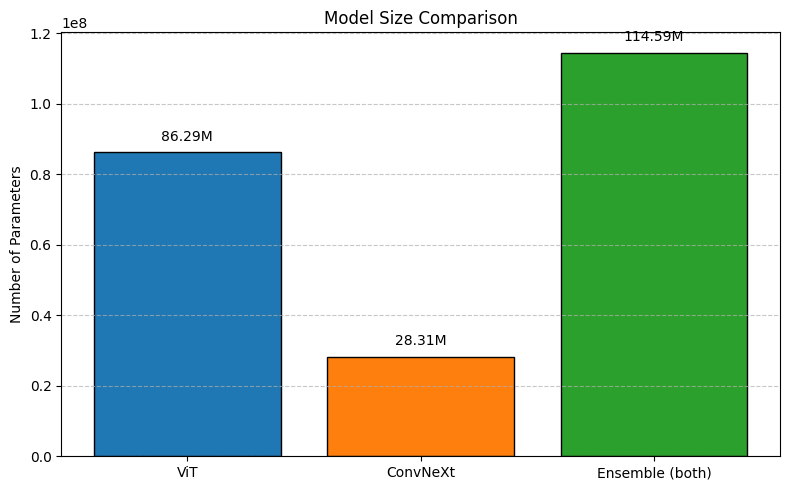

In [ ]:
# ============================================================
# Model Comparison: Number of Parameters
# ============================================================

import torch
import matplotlib.pyplot as plt

def count_parameters(model):
    """Count trainable parameters in a PyTorch model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ----- Count parameters for ViT -----
vit_params = count_parameters(vit_model)
print(f"ViT trainable parameters: {vit_params:,}")

# ----- Count parameters for ConvNeXt -----
convnext_params = count_parameters(convnext_model)
print(f"ConvNeXt trainable parameters: {convnext_params:,}")

# ----- Optional: total for ensemble (both models together) -----
ensemble_params = vit_params + convnext_params
print(f"Ensemble (ViT + ConvNeXt) total parameters: {ensemble_params:,}")

# ----- Bar chart comparison -----
models = ['ViT', 'ConvNeXt', 'Ensemble (both)']
params = [vit_params, convnext_params, ensemble_params]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models, params, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='k')
ax.set_ylabel('Number of Parameters')
ax.set_title('Model Size Comparison')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on bars (in millions for readability)
for bar, val in zip(bars, params):
    millions = val / 1e6
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02 * max(params),
            f'{millions:.2f}M', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Per‑Class Accuracy + Example Visualizations
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict

# ============================================================
# COMPARE PER‑CLASS ACCURACIES: ViT vs ConvNeXt vs Ensemble
# ============================================================

# We already have from the ensemble block:
#   y_test, vit_test_preds, convnext_test_preds, test_preds, classes, num_classes
# Compute per-class accuracies for all three

def per_class_accuracy(y_true, y_pred, num_classes):
    cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
    correct_per_class = np.diag(cm)
    total_per_class = cm.sum(axis=1)
    acc_per_class = np.divide(correct_per_class, total_per_class,
                              out=np.zeros_like(correct_per_class, dtype=float),
                              where=total_per_class != 0)
    return acc_per_class, total_per_class

vit_acc, vit_total = per_class_accuracy(y_test, vit_test_preds, num_classes)
cnx_acc, cnx_total = per_class_accuracy(y_test, convnext_test_preds, num_classes)
ens_acc, ens_total = per_class_accuracy(y_test, test_preds, num_classes)

# Create list of (class_name, vit_acc, cnx_acc, ens_acc, support) for classes with support > 0
class_stats = []
for i, cls in enumerate(classes):
    if vit_total[i] > 0:  # support > 0
        class_stats.append((cls, vit_acc[i], cnx_acc[i], ens_acc[i], vit_total[i]))

# Sort by difference (ViT - ConvNeXt) descending
vit_better = sorted(class_stats, key=lambda x: x[1] - x[2], reverse=True)
cnx_better = sorted(class_stats, key=lambda x: x[2] - x[1], reverse=True)

print("\n" + "="*70)
print("TOP 10 CLASSES WHERE ViT OUTPERFORMS ConvNeXt")
print("="*70)
print(f"{'Class':<30} {'ViT Acc':>8} {'ConvNeXt Acc':>12} {'Diff (ViT-CNX)':>16} {'Support':>8}")
for cls, v, c, e, sup in vit_better[:10]:
    diff = v - c
    print(f"{cls:<30} {v:>7.2%} {c:>11.2%} {diff:>+15.2%} {sup:>8}")

print("\n" + "="*70)
print("TOP 10 CLASSES WHERE ConvNeXt OUTPERFORMS ViT")
print("="*70)
print(f"{'Class':<30} {'ConvNeXt Acc':>12} {'ViT Acc':>8} {'Diff (CNX-ViT)':>16} {'Support':>8}")
for cls, v, c, e, sup in cnx_better[:10]:
    diff = c - v
    print(f"{cls:<30} {c:>11.2%} {v:>7.2%} {diff:>+15.2%} {sup:>8}")




# ============================================================
# Save per-class accuracies to CSV
# ============================================================
import pandas as pd
df_per_class = pd.DataFrame({
    'Class': classes,
    'Support': vit_total,
    'ViT_Accuracy': vit_acc,
    'ConvNeXt_Accuracy': cnx_acc,
    'Ensemble_Accuracy': ens_acc
})
csv_path = os.path.join(SAVE_DIR, 'per_class_accuracies.csv')
df_per_class.to_csv(csv_path, index=False, float_format='%.4f')
print(f"✅ Per-class accuracies saved to: {csv_path}")


TOP 10 CLASSES WHERE ViT OUTPERFORMS ConvNeXt
Class                           ViT Acc ConvNeXt Acc   Diff (ViT-CNX)  Support
Chatmohar Upazila,Pabna        100.00%      50.00%         +50.00%        2
Gopalganj Sadar Upazila,Gopalganj 100.00%      50.00%         +50.00%        2
Jamalganj Upazila,Sunamganj    100.00%      50.00%         +50.00%        2
Kabirhat Upazila,Noakhali      100.00%      50.00%         +50.00%        2
Kalaroa Upazila,Satkhira       100.00%      50.00%         +50.00%        2
Kaliganj Upazila,Gazipur       100.00%      50.00%         +50.00%        2
Kanaighat Upazila,Sylhet       100.00%      50.00%         +50.00%        2
Mohammadpur Upazila,Magura     100.00%      50.00%         +50.00%        2
Monohargonj Upazila,Cumilla    100.00%      50.00%         +50.00%        2
Naria Upazila,Shariatpur       100.00%      50.00%         +50.00%        2

TOP 10 CLASSES WHERE ConvNeXt OUTPERFORMS ViT
Class                          ConvNeXt Acc  ViT Acc   Diff (CNX


📸 Displaying example images for different prediction categories...


/tmp/ipykernel_450/3416775509.py:65: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


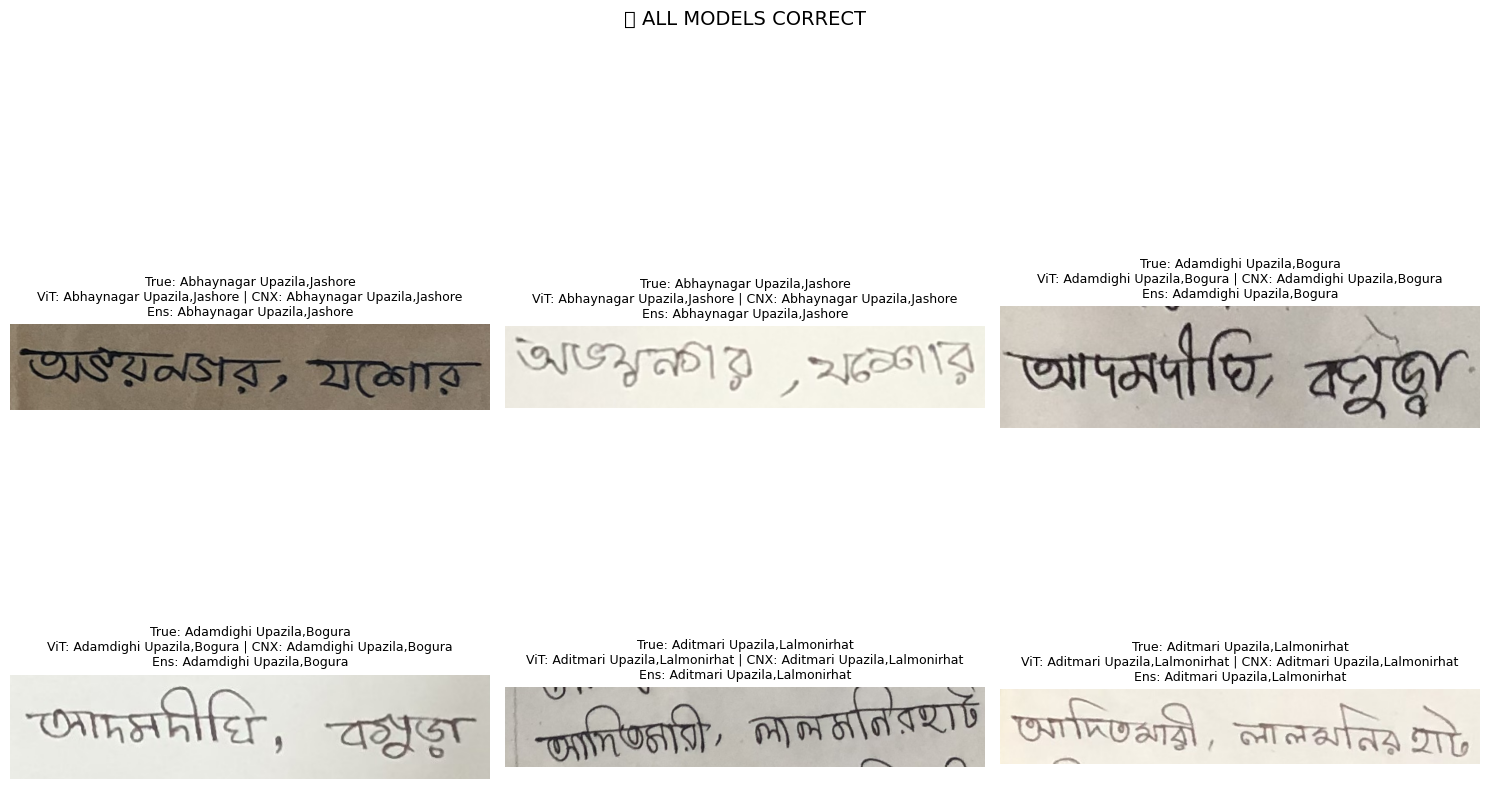

/tmp/ipykernel_450/3416775509.py:65: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


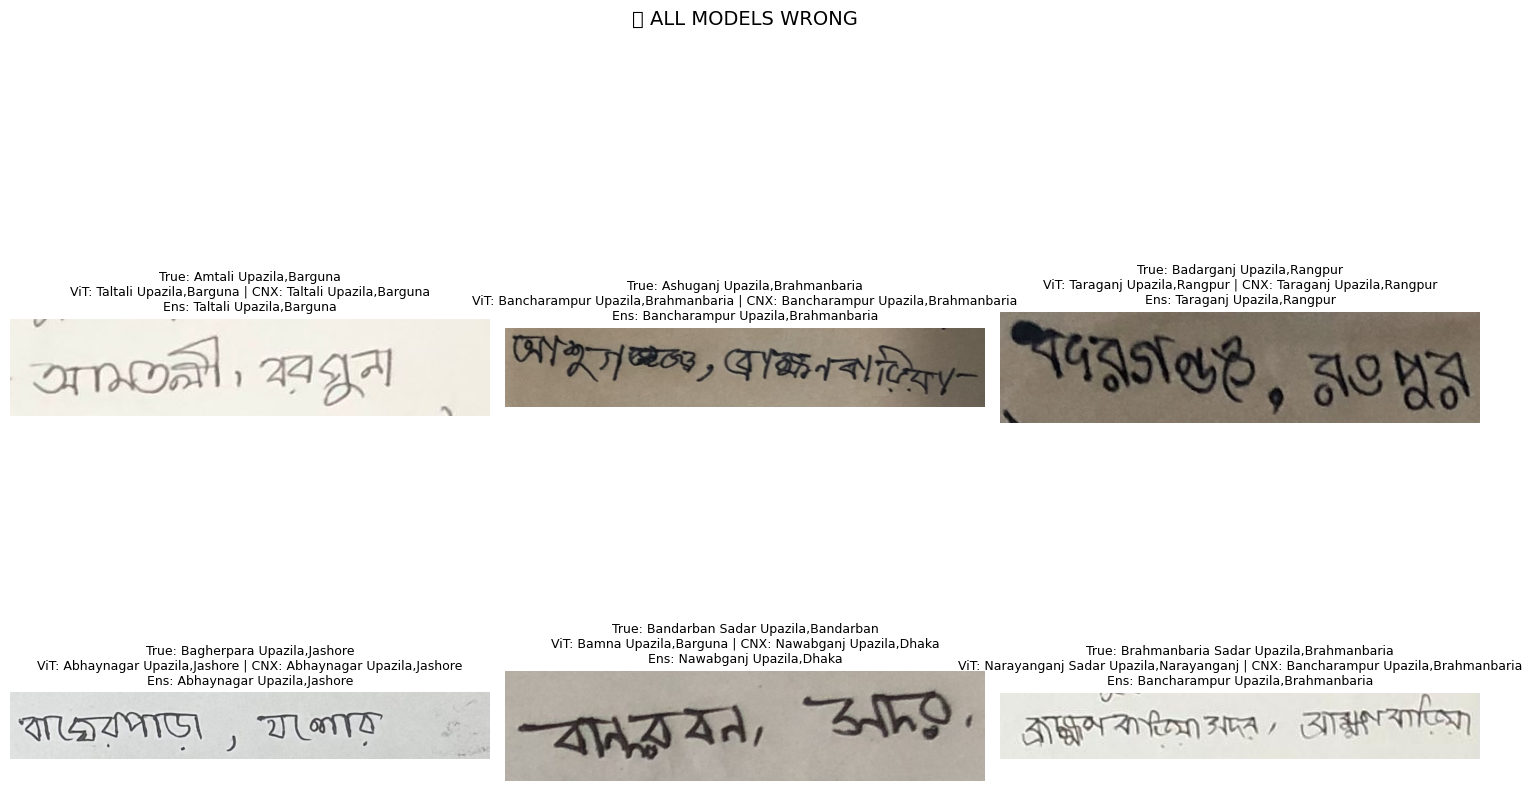

/tmp/ipykernel_450/3416775509.py:65: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


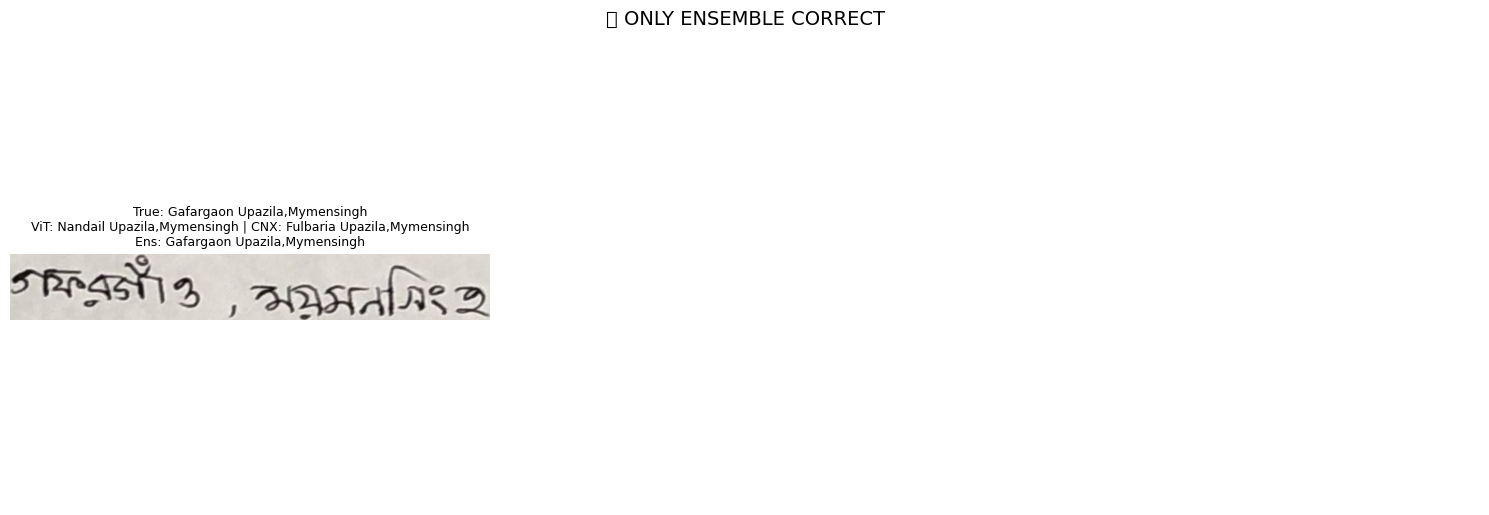

/tmp/ipykernel_450/3416775509.py:65: UserWarning: Glyph 128312 (\N{SMALL ORANGE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128312 (\N{SMALL ORANGE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


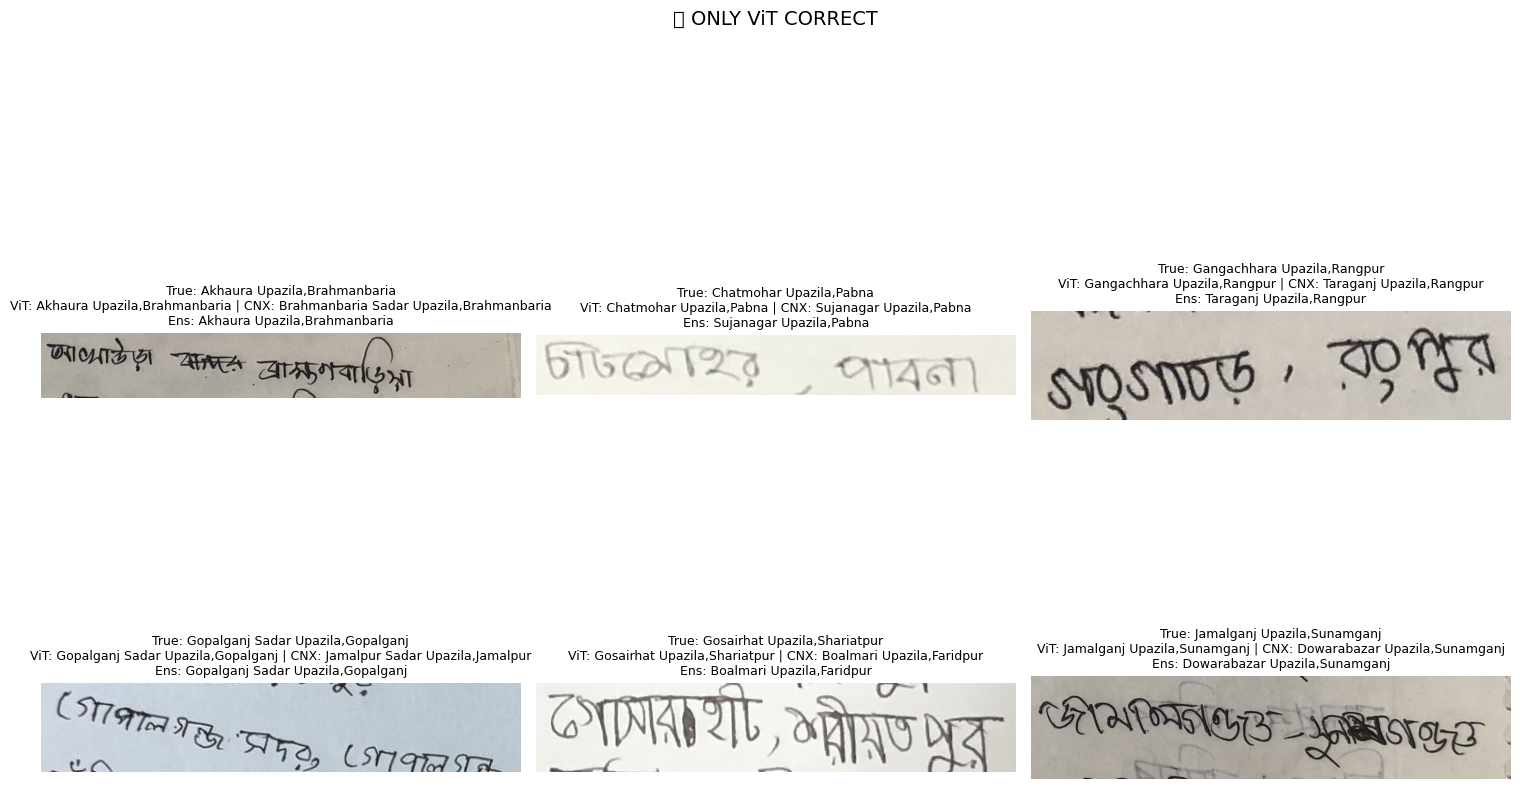

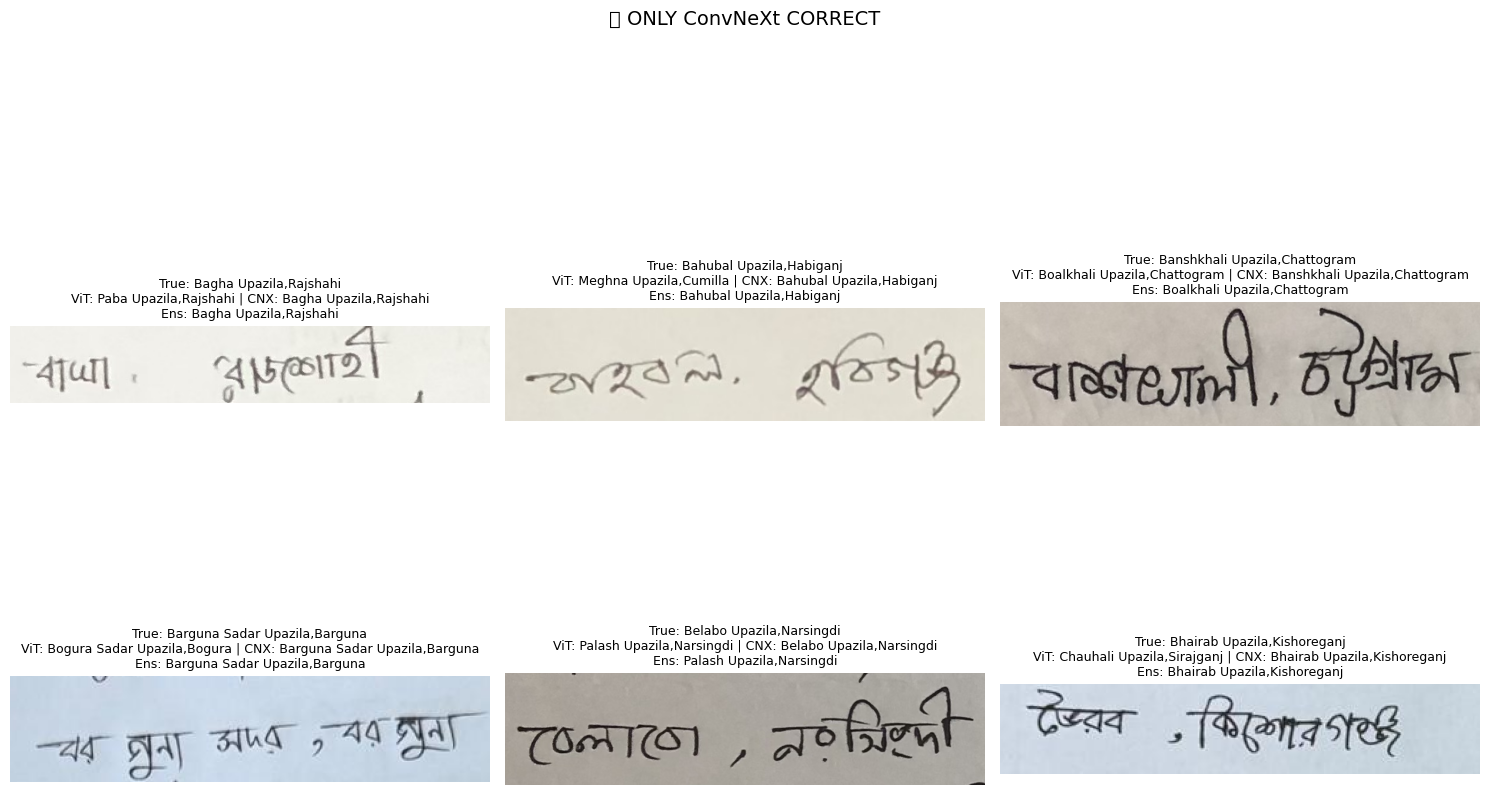


TOP CONFUSION PAIRS – ENSEMBLE

Dohar Upazila,Dhaka → Savar Upazila,Dhaka: 2 images


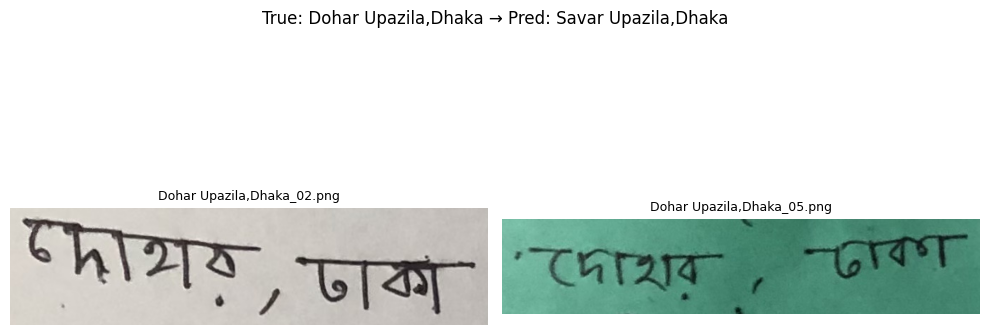


Daganbhuiyan Upazila,Feni → Chagalnaiya Upazila,Feni: 2 images


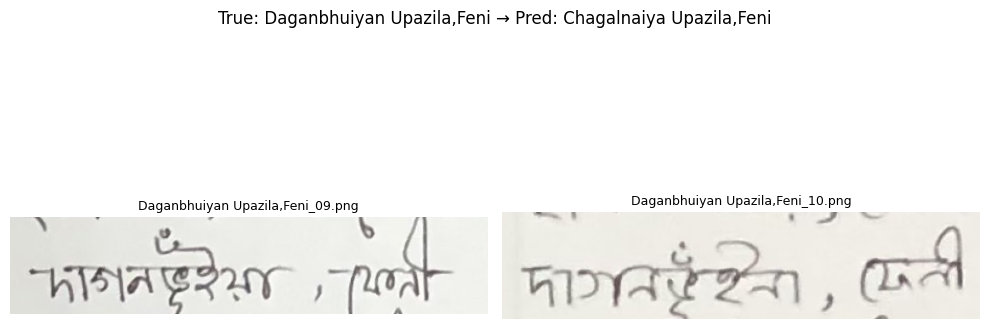


Zajira Upazila,Shariatpur → Naria Upazila,Shariatpur: 1 images


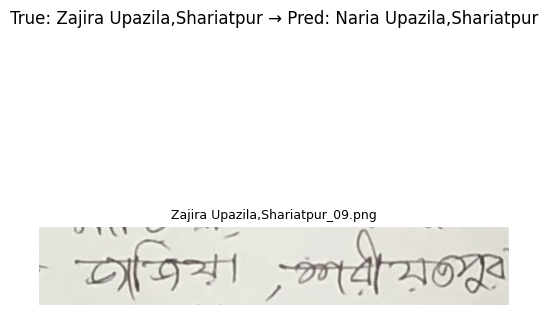


✅ Additional evaluation completed.


In [ ]:
# ============================================================
# Detailed Sample Analysis: Correct/Wrong Categories and Confusions
# ============================================================

import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from sklearn.metrics import confusion_matrix

# -------------------------
# 1. Verify lengths match
# -------------------------
assert len(test_paths) == len(y_test) == len(vit_test_preds) == len(convnext_test_preds) == len(test_preds), \
    "Length mismatch between test paths, labels, and predictions."

# -------------------------
# 2. Build a list of dictionaries for each test sample
# -------------------------
samples = []
for i in range(len(y_test)):
    samples.append({
        "path": test_paths[i],
        "true": y_test[i],
        "true_name": classes[y_test[i]],
        "vit_pred": vit_test_preds[i],
        "vit_name": classes[vit_test_preds[i]],
        "cnx_pred": convnext_test_preds[i],
        "cnx_name": classes[convnext_test_preds[i]],
        "ens_pred": test_preds[i],
        "ens_name": classes[test_preds[i]],
    })

# -------------------------
# 3. Helper to show examples in a grid (already handles single axes correctly)
# -------------------------
def show_examples_grid(title, items, k=6, cols=3):
    """Display up to k images in a grid of `cols` columns."""
    if not items:
        print(f"No examples for: {title}")
        return
    n = min(len(items), k)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows))  # increased figure size
    # Flatten axes if multiple, or put single axes in a list
    if rows * cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    fig.suptitle(title, fontsize=14, y=1.02)
    for i in range(n):
        it = items[i]
        img = Image.open(it["path"]).convert("RGB")
        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(
            f"True: {it['true_name']}\n"
            f"ViT: {it['vit_name']} | CNX: {it['cnx_name']}\n"
            f"Ens: {it['ens_name']}",
            fontsize=9
        )
    # Turn off unused axes
    for j in range(n, rows*cols):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

# -------------------------
# 4. Select and display different categories
# -------------------------
# Correct predictions by all models
all_correct = [s for s in samples if s["vit_pred"] == s["true"] and s["cnx_pred"] == s["true"] and s["ens_pred"] == s["true"]]
# Wrong by all
all_wrong = [s for s in samples if s["vit_pred"] != s["true"] and s["cnx_pred"] != s["true"] and s["ens_pred"] != s["true"]]
# Ensemble correct but both individual wrong
ensemble_only_correct = [s for s in samples if s["ens_pred"] == s["true"] and s["vit_pred"] != s["true"] and s["cnx_pred"] != s["true"]]
# ViT correct, ConvNeXt wrong (ensemble may be anything)
vit_only_correct = [s for s in samples if s["vit_pred"] == s["true"] and s["cnx_pred"] != s["true"]]
# ConvNeXt correct, ViT wrong
cnx_only_correct = [s for s in samples if s["cnx_pred"] == s["true"] and s["vit_pred"] != s["true"]]

print("\n📸 Displaying example images for different prediction categories...")
show_examples_grid("✅ ALL MODELS CORRECT", all_correct, k=6)
show_examples_grid("❌ ALL MODELS WRONG", all_wrong, k=6)
if ensemble_only_correct:
    show_examples_grid("🔹 ONLY ENSEMBLE CORRECT", ensemble_only_correct, k=6)
if vit_only_correct:
    show_examples_grid("🔸 ONLY ViT CORRECT", vit_only_correct, k=6)
if cnx_only_correct:
    show_examples_grid("🔸 ONLY ConvNeXt CORRECT", cnx_only_correct, k=6)

# -------------------------
# 5. Show top confusions for ensemble
# -------------------------
def show_top_confusion_samples(y_true, y_pred, samples, classes, n_pairs=3, n_per_pair=2):
    # Find most frequent confusion pairs (true ≠ pred)
    cm = confusion_matrix(y_true, y_pred)
    confusions = []
    for i in range(len(classes)):
        for j in range(len(classes)):
            if i != j and cm[i, j] > 0:
                confusions.append((cm[i, j], i, j))
    confusions.sort(reverse=True)  # by count

    print("\n" + "="*80)
    print("TOP CONFUSION PAIRS – ENSEMBLE")
    print("="*80)
    for cnt, true_idx, pred_idx in confusions[:n_pairs]:
        true_name = classes[true_idx]
        pred_name = classes[pred_idx]
        print(f"\n{true_name} → {pred_name}: {cnt} images")
        # Find examples of this confusion
        examples = [s for s in samples if s["true"] == true_idx and s["ens_pred"] == pred_idx]
        if not examples:
            continue
        n_examples = min(len(examples), n_per_pair)
        fig, axes = plt.subplots(1, n_examples, figsize=(5*n_examples, 5))  # larger size
        # Ensure axes is always a list for consistent indexing
        if n_examples == 1:
            axes = [axes]
        fig.suptitle(f"True: {true_name} → Pred: {pred_name}", fontsize=12)
        for i, ex in enumerate(examples[:n_examples]):
            img = Image.open(ex["path"]).convert("RGB")
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(os.path.basename(ex["path"]), fontsize=9)
        plt.tight_layout()
        plt.show()

show_top_confusion_samples(y_test, test_preds, samples, classes, n_pairs=3, n_per_pair=2)

print("\n✅ Additional evaluation completed.")

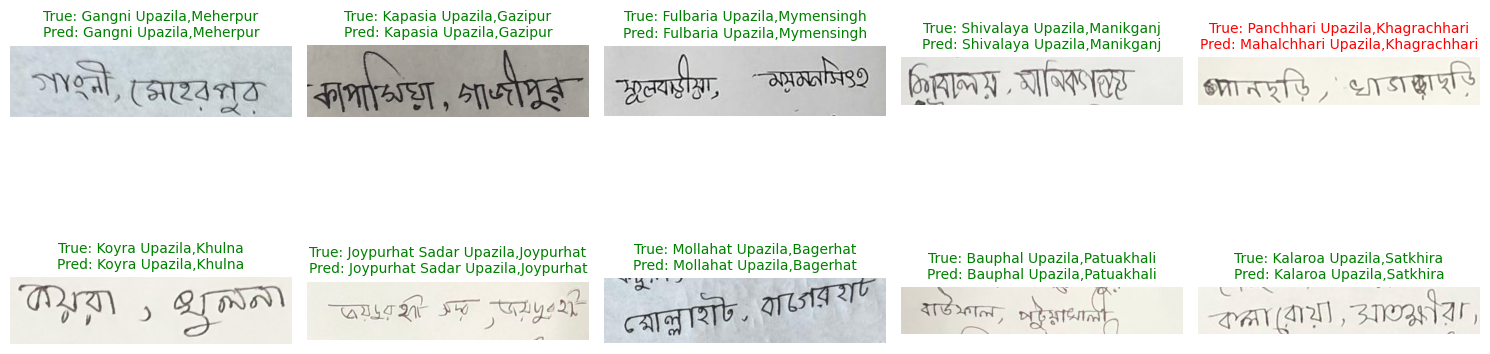

In [ ]:
# ============================================================
# Random Sample Predictions (Best Ensemble) – New Random Set Each Run
# ============================================================

import random
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# ----- 1. Get test paths and ensure alignment -----
test_paths = [s[0] for s in test_ds.samples]   # paths in dataset order
assert len(test_paths) == len(y_test) == len(test_preds), "Length mismatch!"

# ----- 2. Randomly select 10 indices (no seed – new each time) -----
indices = random.sample(range(len(y_test)), 10)

# ----- 3. Create a 2x5 grid -----
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, idx in enumerate(indices):
    # Load and display image
    img_path = test_paths[idx]
    img = Image.open(img_path).convert("RGB")
    axes[i].imshow(img)
    axes[i].axis("off")

    # Get true and predicted labels
    true_label = classes[y_test[idx]]
    pred_label = classes[test_preds[idx]]
    correct = (y_test[idx] == test_preds[idx])

    # Set title with color
    title = f"True: {true_label}\nPred: {pred_label}"
    color = 'green' if correct else 'red'
    axes[i].set_title(title, color=color, fontsize=10)

# Hide any unused axes (should not happen with 10 images)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Classification Report (Weighted Soft‑Voting Ensemble)
# Focus on True Positive Rate (Recall)
# ============================================================

import numpy as np
from sklearn.metrics import classification_report, recall_score

# Check that required variables exist
assert 'best_soft_weights' in dir(), "best_soft_weights not found – run the ensemble optimization first."
assert 'test_logits_stack' in dir(), "test_logits_stack not found – run logit collection first."
assert 'y_test' in dir(), "y_test not found."
assert 'classes' in dir(), "classes not found."

# Compute soft‑voting predictions on the test set using the optimal weights
weighted_test_logits = np.tensordot(test_logits_stack, best_soft_weights, axes=(1, 0))
test_preds_soft = np.argmax(weighted_test_logits, axis=1)

# Overall test accuracy
test_acc_soft = (test_preds_soft == y_test).mean()
print(f"\n🔹 Weighted Soft‑Voting Test Accuracy: {test_acc_soft:.4f}\n")

# Full classification report (includes recall per class)
print("=" * 70)
print("CLASSIFICATION REPORT – WEIGHTED SOFT VOTING")
print("=" * 70)
print(classification_report(y_test, test_preds_soft, target_names=classes, zero_division=0))

# Focus on recall (True Positive Rate)
recall_per_class = recall_score(y_test, test_preds_soft, average=None, zero_division=0)

print("\n📊 Per‑Class Recall (True Positive Rate):")
print("-" * 50)
for cls, rec in zip(classes, recall_per_class):
    print(f"{cls:<30}: {rec:.4f}")

# Macro and weighted average recall
macro_rec = recall_score(y_test, test_preds_soft, average='macro')
weighted_rec = recall_score(y_test, test_preds_soft, average='weighted')
print("-" * 50)
print(f"{'Macro Average Recall':<30}: {macro_rec:.4f}")
print(f"{'Weighted Average Recall':<30}: {weighted_rec:.4f}")


🔹 Weighted Soft‑Voting Test Accuracy: 0.9465

CLASSIFICATION REPORT – WEIGHTED SOFT VOTING
                                          precision    recall  f1-score   support

              Abhaynagar Upazila,Jashore       0.67      1.00      0.80         2
                Adamdighi Upazila,Bogura       1.00      1.00      1.00         2
            Aditmari Upazila,Lalmonirhat       1.00      1.00      1.00         2
             Agailjhara Upazila,Barishal       1.00      1.00      1.00         2
             Ajmiriganj Upazila,Habiganj       1.00      1.00      1.00         2
            Akhaura Upazila,Brahmanbaria       1.00      1.00      1.00         3
              Akkelpur Upazila,Joypurhat       1.00      1.00      1.00         2
             Alamdanga Upazila,Chuadanga       1.00      1.00      1.00         2
              Alfadanga Upazila,Faridpur       1.00      1.00      1.00         2
             Ali Kadam Upazila,Bandarban       1.00      1.00      1.00         3
     

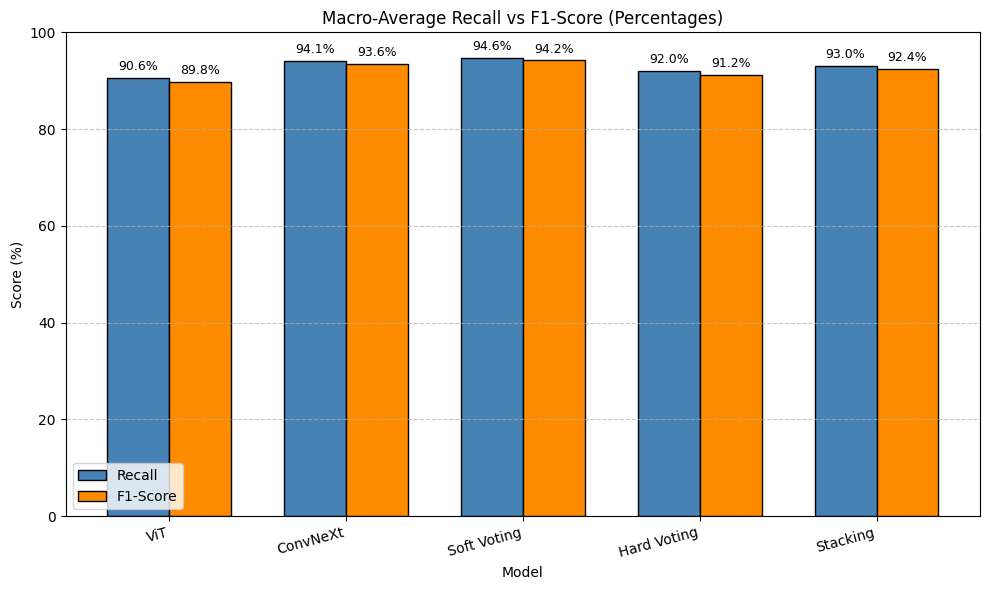

✅ Grouped bar chart saved to: /content/drive/MyDrive/Thesis_project/models/recall_f1_grouped.png

📊 Macro‑Average Scores (%):
ViT          → Recall: 90.6%   F1: 89.8%
ConvNeXt     → Recall: 94.1%   F1: 93.6%
Soft Voting  → Recall: 94.6%   F1: 94.2%
Hard Voting  → Recall: 92.0%   F1: 91.2%
Stacking     → Recall: 93.0%   F1: 92.4%


In [ ]:
# ============================================================
# Grouped Bar Chart: Recall vs F1 for Each Model (Percentages)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

# ----- 1. Collect predictions for all five models -----
vit_preds = vit_test_preds
cnx_preds = convnext_test_preds

# Soft voting (using optimal weights)
weighted_test_logits = np.tensordot(test_logits_stack, best_soft_weights, axes=(1, 0))
soft_preds = np.argmax(weighted_test_logits, axis=1)

# Hard voting (majority vote)
hard_preds_classes = np.argmax(test_logits_stack, axis=-1)  # (N, 2)
hard_preds = np.array([np.argmax(np.bincount(sample)) for sample in hard_preds_classes])

# Stacking (using final meta‑classifier)
X_test_meta = test_probs_stack.reshape(test_probs_stack.shape[0], -1)
stack_preds = final_meta_clf.predict(X_test_meta)

# ----- 2. Compute macro recall and macro F1 (as percentages) -----
models = {
    'ViT': vit_preds,
    'ConvNeXt': cnx_preds,
    'Soft Voting': soft_preds,
    'Hard Voting': hard_preds,
    'Stacking': stack_preds
}

model_names = list(models.keys())
recall_vals = []
f1_vals = []

for name, preds in models.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, preds, average=None, zero_division=0
    )
    recall_vals.append(np.mean(recall) * 100)   # percentage
    f1_vals.append(np.mean(f1) * 100)

# ----- 3. Create grouped bar chart -----
x = np.arange(len(model_names))          # label locations
width = 0.35                              # width of each bar

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, recall_vals, width, label='Recall', color='steelblue', edgecolor='k')
bars2 = ax.bar(x + width/2, f1_vals,     width, label='F1-Score', color='darkorange', edgecolor='k')

# Add labels, title, and custom x‑axis tick labels
ax.set_xlabel('Model')
ax.set_ylabel('Score (%)')
ax.set_title('Macro‑Average Recall vs F1‑Score (Percentages)')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylim([0, 100])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Attach value labels on top of each bar
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1,
            f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1,
            f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()

# Save plot
plot_path = os.path.join(SAVE_DIR, 'recall_f1_grouped.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Grouped bar chart saved to: {plot_path}")

# ----- 4. Print numerical values -----
print("\n📊 Macro‑Average Scores (%):")
for i, name in enumerate(model_names):
    print(f"{name:12} → Recall: {recall_vals[i]:.1f}%   F1: {f1_vals[i]:.1f}%")

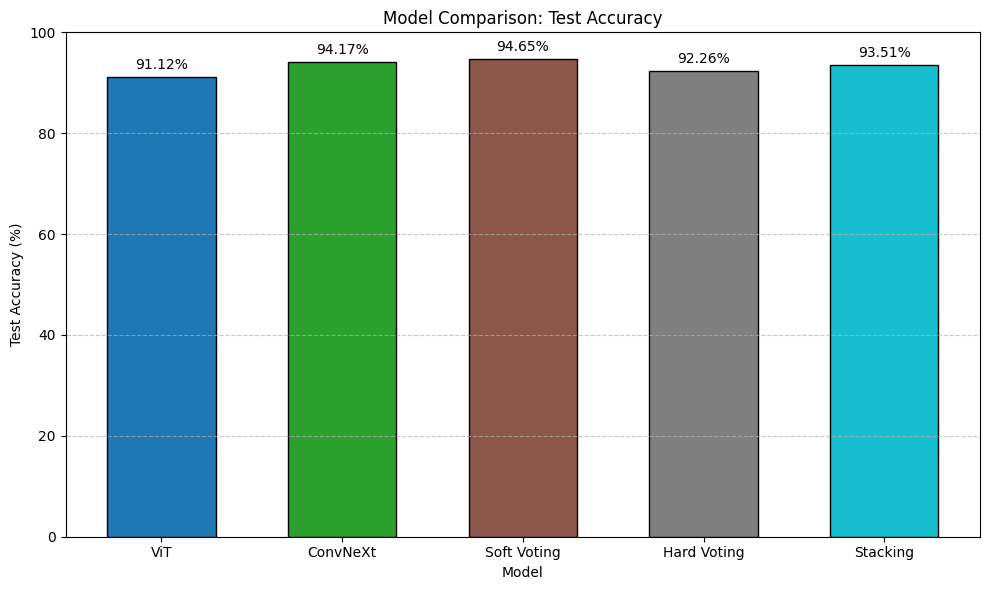

✅ Test accuracy comparison plot (colored bars) saved to: /content/drive/MyDrive/Thesis_project/models/test_accuracy_comparison_colored.png

📊 Test Accuracies (%):
ViT         : 91.12%
ConvNeXt    : 94.17%
Soft Voting : 94.65%
Hard Voting : 92.26%
Stacking    : 93.51%


In [ ]:
# ============================================================
# Model Comparison: Test Accuracy (Distinct Colors per Model)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# ----- 1. Compute test accuracies for all five models -----
# (Assumes predictions from earlier cells are available)
models = {
    'ViT': vit_test_preds,
    'ConvNeXt': convnext_test_preds,
    'Soft Voting': soft_preds,
    'Hard Voting': hard_preds,
    'Stacking': stack_preds
}

model_names = list(models.keys())
accuracies = [accuracy_score(y_test, preds) * 100 for preds in models.values()]  # percentages

# ----- 2. Assign distinct colors -----
colors = plt.cm.tab10(np.linspace(0, 1, len(models)))   # unique colors from tab10

# ----- 3. Create bar chart -----
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(model_names, accuracies, color=colors, edgecolor='k', width=0.6)

# Add labels and title
ax.set_xlabel('Model')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Model Comparison: Test Accuracy')
ax.set_ylim([0, 100])
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of bars
for bar, val in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()

# Save plot
plot_path = os.path.join(SAVE_DIR, 'test_accuracy_comparison_colored.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Test accuracy comparison plot (colored bars) saved to: {plot_path}")

# ----- 4. Print numerical values -----
print("\n📊 Test Accuracies (%):")
for name, acc in zip(model_names, accuracies):
    print(f"{name:12}: {acc:.2f}%")